In [17]:
import pickle
import time
import tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.neighbors import NearestNeighbors

In [18]:
TRAIN_SIZE = 10000     
TEST_SIZE = 500   
K_NEIGHBORS = 10
SEED = 42


In [19]:
import gc
import os
import threading

import faiss
import psutil
from threadpoolctl import threadpool_limits


_process = psutil.Process(os.getpid())


N_THREADS = 1
threadpool_limits(N_THREADS)
faiss.omp_set_num_threads(N_THREADS)
MB = 1024 * 1024
# Зёрна равны значениям по умолчанию faiss (k-means) и hnswlib; заданы явно,
# чтобы Recall не зависел от версии библиотек
FAISS_KMEANS_SEED = 1234
HNSW_SEED = 100

def get_process_memory_mb():
    return _process.memory_info().rss / MB


class MemoryMeter:
    """RSS процесса до блока, после блока и максимум внутри блока.

    Разность «после − до» не видит временные буферы, освобождённые к концу блока
    (матрица расстояний, хеши запросов), поэтому RSS дополнительно опрашивается
    в фоновом потоке и фиксируется пик. Перед замером собирается мусор, чтобы
    в «до» не попали объекты, ожидающие удаления.
    """

    def __init__(self, interval=0.001):
        self.interval = interval

    def __enter__(self):
        gc.collect()
        self.before = self.peak = _process.memory_info().rss
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._poll, daemon=True)
        self._thread.start()
        return self

    def _poll(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, _process.memory_info().rss)
            self._stop.wait(self.interval)

    def __exit__(self, *exc):
        self._stop.set()
        self._thread.join()
        self.after = _process.memory_info().rss
        self.peak = max(self.peak, self.after)

    @property
    def delta_mb(self):
        """После − до. Зависит от истории процесса (переиспользование освобождённой
        памяти, выгрузка страниц), поэтому размер индекса считается отдельно."""
        return (self.after - self.before) / MB

    @property
    def peak_delta_mb(self):
        return (self.peak - self.before) / MB


def measure_time(fn, repeats=7, warmup=1):
    result = None
    for _ in range(warmup):
        result = fn()
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        result = fn()
        times.append(time.perf_counter() - t0)
    return result, float(np.median(times))

In [20]:
X_mnist, _ = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, parser="auto")

X_mnist = X_mnist.astype(np.float32) / 255.0

X_train = X_mnist[:TRAIN_SIZE]
X_test = X_mnist[TRAIN_SIZE:TRAIN_SIZE + TEST_SIZE]

print(f"Размер обучающей выборки (Train): {X_train.shape}")
print(f"Размер тестовой выборки (Test):   {X_test.shape}")

Размер обучающей выборки (Train): (10000, 784)
Размер тестовой выборки (Test):   (500, 784)


In [21]:
with MemoryMeter() as mem_fit:
    start_time_fit = time.perf_counter()

    nn_brute_force = NearestNeighbors(n_neighbors=K_NEIGHBORS, algorithm="brute", metric="euclidean")
    nn_brute_force.fit(X_train)

    execution_time_fit = time.perf_counter() - start_time_fit
memory_fit_brut_force = mem_fit.delta_mb
index_mb_brut_force = nn_brute_force._fit_X.nbytes / MB


def search_brut_force():
    return nn_brute_force.kneighbors(X_test)


(distances, indices), execution_time_test = measure_time(search_brut_force)

with MemoryMeter() as mem_search:
    search_brut_force()
peak_memory_brut_force = mem_search.peak_delta_mb

print(f"Время обучения:             {execution_time_fit:.4f} сек")
print(f"Время поиска:               {execution_time_test:.4f} сек "
      f"({execution_time_test / len(X_test) * 1e3:.3f} мс/запрос)")
print(f"Размер индекса:             {index_mb_brut_force:.2f} MB")
print(f"ΔRSS после обучения:        {memory_fit_brut_force:.2f} MB")
print(f"Пиковое потребление памяти: {peak_memory_brut_force:.2f} MB "
      f"(после − до: {mem_search.delta_mb:.2f} MB)")

Время обучения:             0.0337 сек
Время поиска:               0.3316 сек (0.663 мс/запрос)
Размер индекса:             29.91 MB
ΔRSS после обучения:        29.77 MB
Пиковое потребление памяти: 4.59 MB (после − до: 0.02 MB)


In [22]:
from pathlib import Path
BASE_WEIGHT_PATH = Path("./weights")
BASE_WEIGHT_PATH.mkdir(parents=True, exist_ok=True)

full_path = BASE_WEIGHT_PATH / "mnist_exact_k10.pkl"

payload = {
    "indices": indices,
    "distances": distances,  
    "K": K_NEIGHBORS,
    "execution_time": execution_time_test,
    "peak_memory_mb": peak_memory_brut_force,
    "n_train": X_train.shape[0],
    "n_test": X_test.shape[0],
}

with open(full_path, "wb") as f:
    pickle.dump(payload, f)

print(f"Результаты точного поиска сохранены в файл: {full_path}")

Результаты точного поиска сохранены в файл: weights\mnist_exact_k10.pkl


In [23]:
def load_ground_truth(pkl_filepath: str):
    with open(pkl_filepath, "rb") as f:
        gt_data = pickle.load(f)
    return gt_data["indices"]


def calculate_recall_at_k(exact_indices: np.ndarray, approx_indices: np.ndarray, k: int = K_NEIGHBORS) -> float:
    exact_k = exact_indices[:, :k]
    approx_k = approx_indices[:, :k]

    n_queries = exact_k.shape[0]
    total_recall = 0.0

    for i in range(n_queries):
        true_set = set(exact_k[i])
        found_set = set(approx_k[i])

        intersection = len(true_set.intersection(found_set))
        total_recall += intersection / k

    return total_recall / n_queries

## Flyhash

## FlyHash optim

In [24]:
import faiss
from scipy import sparse
from flyhash import FlyHash

exact_indices = load_ground_truth(full_path)

K = K_NEIGHBORS
INPUT_DIM = X_train.shape[1]
HASH_DIM = 7840
SPARSITY = 0.05

fly = FlyHash(
    input_dim=INPUT_DIM,
    hash_dim=HASH_DIM,
    sparsity=SPARSITY,
    seed=SEED,
)


def hash_to_packed(model, X):
    hs = model(X)
    if sparse.issparse(hs):
        hs = hs.toarray()
    bits = (np.asarray(hs) > 0).astype(np.uint16)
    return np.ascontiguousarray(np.packbits(bits, axis=1))


with MemoryMeter() as mem_fit:
    t0 = time.perf_counter()
    train_hashes = hash_to_packed(fly, X_train)
    index_fly = faiss.IndexBinaryFlat(HASH_DIM)
    index_fly.add(train_hashes)
    time_hash_train_fly = time.perf_counter() - t0
memory_fit_fly_mb = mem_fit.delta_mb
index_mb_fly = (index_fly.ntotal * index_fly.code_size + fly.projection_matrix.nbytes) / MB


def search_fly():
    test_hashes = hash_to_packed(fly, X_test)
    return index_fly.search(test_hashes, K)


(_, approx_indices_fly), time_search_fly = measure_time(search_fly)


test_hashes, time_hash_test_fly = measure_time(lambda: hash_to_packed(fly, X_test))
_, time_hamming_fly = measure_time(lambda: index_fly.search(test_hashes, K))


with MemoryMeter() as mem_search:
    search_fly()
peak_memory_fly_mb = mem_search.peak_delta_mb


print("=== Результаты FlyHash ===")
print(f"Параметры: hash_dim={HASH_DIM}, sparsity={SPARSITY}")
print(f"Хеширование Train (Время обучения): {time_hash_train_fly:.4f} сек")
print(f"Время поиска (Inc. Test Hash):       {time_search_fly:.4f} сек "
      f"({time_search_fly / len(X_test) * 1e3:.3f} мс/запрос)")
print(f"  хеширование Test:                  {time_hash_test_fly:.4f} сек")
print(f"  поиск по Хэммингу:                 {time_hamming_fly:.4f} сек")
print(f"Размер индекса (коды + проекции):   {index_mb_fly:.2f} MB")
print(f"ΔRSS после обучения:                {memory_fit_fly_mb:.2f} MB")
print(
    f"Пиковое потребление памяти:        {peak_memory_fly_mb:.2f} MB "
    f"(после − до: {mem_search.delta_mb:.2f} MB)\n"
)

for k in (1, 5, 10):
    recall = calculate_recall_at_k(exact_indices, approx_indices_fly, k)
    print(f"Recall@{k}: {recall:.4f}")

=== Результаты FlyHash ===
Параметры: hash_dim=7840, sparsity=0.05
Хеширование Train (Время обучения): 3.8168 сек
Время поиска (Inc. Test Hash):       0.8389 сек (1.678 мс/запрос)
  хеширование Test:                  0.2008 сек
  поиск по Хэммингу:                 0.6237 сек
Размер индекса (коды + проекции):   15.21 MB
ΔRSS после обучения:                30.46 MB
Пиковое потребление памяти:        38.43 MB (после − до: 0.48 MB)

Recall@1: 0.6120
Recall@5: 0.6472
Recall@10: 0.6668


### HNSW

In [ ]:
import hnswlib

BASE_WEIGHT_PATH = Path("./weights")
full_path = BASE_WEIGHT_PATH / "mnist_exact_k10.pkl"

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)


with open(full_path, "rb") as f:
    gt_data = pickle.load(f)
exact_indices = np.asarray(gt_data["indices"])


dim = X_train.shape[1]
num_elements = X_train.shape[0]

M = 16
EF_CONSTRUCTION = 200
EF_SEARCH = 50
K = K_NEIGHBORS

with MemoryMeter() as mem_fit:
    t0 = time.perf_counter()

    p = hnswlib.Index(space="l2", dim=dim)
    p.init_index(max_elements=num_elements, ef_construction=EF_CONSTRUCTION, M=M,
                 random_seed=SEED)
    p.set_num_threads(N_THREADS)
    p.add_items(X_train)
    p.set_ef(EF_SEARCH)

    time_fit_hnsw = time.perf_counter() - t0
memory_fit_hnsw_mb = mem_fit.delta_mb
index_mb_hnsw = p.index_file_size() / MB


def search_hnsw():
    return p.knn_query(X_test, k=K)  # Здесь поиск


(hnsw_indices, _), time_test_hnsw = measure_time(search_hnsw)

with MemoryMeter() as mem_search:
    search_hnsw()
hnsw_index_memory_mb = mem_search.peak_delta_mb


print("=== Результаты HNSW ===")
print(f"Параметры: M={M}, ef_construction={EF_CONSTRUCTION}, ef={EF_SEARCH}")
print(f"Время построения индекса:  {time_fit_hnsw:.4f} сек")
print(f"Время поиска:              {time_test_hnsw:.4f} сек "
      f"({time_test_hnsw / len(X_test) * 1e3:.3f} мс/запрос)")
print(f"Размер индекса:            {index_mb_hnsw:.2f} MB")
print(f"ΔRSS после построения:     {memory_fit_hnsw_mb:.2f} MB")
print(f"Пиковое потребление памяти: {hnsw_index_memory_mb:.2f} MB "
      f"(после − до: {mem_search.delta_mb:.2f} MB)\n")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, hnsw_indices, k):.4f}")

=== Результаты HNSW ===
Параметры: M=16, ef_construction=200, ef=50
Время построения индекса:  5.3554 сек
Время поиска:              0.0893 сек (0.179 мс/запрос)
Размер индекса:            31.33 MB
ΔRSS после построения:     34.73 MB
Пиковое потребление памяти: 0.02 MB (после − до: 0.02 MB)

Recall@1: 0.9980
Recall@5: 0.9984
Recall@10: 0.9980


### IVFPQ

In [ ]:
import faiss

BASE_WEIGHT_PATH = Path("./weights")
full_path = BASE_WEIGHT_PATH / "mnist_exact_k10.pkl"

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)


with open(full_path, "rb") as f:
    gt_data = pickle.load(f)
exact_indices = np.asarray(gt_data["indices"])


dim = X_train.shape[1]
nlist = 100
m_subquantizers = 28
bits_per_code = 8
nprobe = 10
K = K_NEIGHBORS


quantizer = faiss.IndexFlatL2(dim)
index = faiss.IndexIVFPQ(quantizer, dim, nlist, m_subquantizers, bits_per_code)
index.use_precomputed_table = 0
index.cp.seed = SEED
index.pq.cp.seed = SEED


with MemoryMeter() as mem_fit:
    t0 = time.perf_counter()

    index.train(X_train)
    index.add(X_train)

    time_train_ivfpq = time.perf_counter() - t0
memory_fit_ivfpq_mb = mem_fit.delta_mb
index_mb_ivfpq = faiss.serialize_index(index).nbytes / MB


index.nprobe = nprobe


def search_ivfpq():
    return index.search(X_test, K)


(distances, ivfpq_indices), time_search_ivfpq = measure_time(search_ivfpq)

with MemoryMeter() as mem_search:
    search_ivfpq()
peak_memory_ivfpq = mem_search.peak_delta_mb


print(f"Параметры: nlist={nlist}, M={m_subquantizers}, "
      f"nbits={bits_per_code}, nprobe={nprobe}")
print(f"Время обучения + добавления: {time_train_ivfpq:.4f} сек")
print(f"Время поиска:                {time_search_ivfpq:.4f} сек "
      f"({time_search_ivfpq / len(X_test) * 1e3:.3f} мс/запрос)")
print(f"Размер индекса:              {index_mb_ivfpq:.2f} MB")
print(f"ΔRSS после обучения:         {memory_fit_ivfpq_mb:.2f} MB")
print(f"Пиковое потребление памяти:  {peak_memory_ivfpq:.2f} MB "
      f"(после − до: {mem_search.delta_mb:.2f} MB)\n")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, ivfpq_indices, k):.4f}")

Параметры: nlist=100, M=28, nbits=8, nprobe=10
Время обучения + добавления: 8.7668 сек
Время поиска:                0.0600 сек (0.120 мс/запрос)
Размер индекса:              1.41 MB
ΔRSS после обучения:         4.13 MB
Пиковое потребление памяти:  0.02 MB (после − до: 0.02 MB)

Recall@1: 0.6280
Recall@5: 0.7256
Recall@10: 0.7514


In [27]:
results = {
    "Exact L2": {
        "indices": exact_indices,     
        "build_time": execution_time_fit,
        "search_time": execution_time_test,
        "index_mb": index_mb_brut_force,
        "build_memory_mb": memory_fit_brut_force,
        "memory_mb": peak_memory_brut_force,
    },
    "HNSW": {
        "indices": hnsw_indices,
        "build_time": time_fit_hnsw,
        "search_time": time_test_hnsw,
        "index_mb": index_mb_hnsw,
        "build_memory_mb": memory_fit_hnsw_mb,
        "memory_mb": hnsw_index_memory_mb,
    },
    "IVFPQ": {
        "indices": ivfpq_indices,
        "build_time": time_train_ivfpq,
        "search_time": time_search_ivfpq,
        "index_mb": index_mb_ivfpq,
        "build_memory_mb": memory_fit_ivfpq_mb,
        "memory_mb": peak_memory_ivfpq,
    },
    "FlyHash": {
        "indices": approx_indices_fly,
        "build_time": time_hash_train_fly,
        "search_time": time_search_fly,
        "index_mb": index_mb_fly,
        "build_memory_mb": memory_fit_fly_mb,
        "memory_mb": peak_memory_fly_mb,
    },
}

n_test = len(X_test)
rows = []
for name, r in results.items():
    row = {
        "Алгоритм": name,
        "Recall@1":  calculate_recall_at_k(exact_indices, r["indices"], 1),
        "Recall@5":  calculate_recall_at_k(exact_indices, r["indices"], 5),
        "Recall@10": calculate_recall_at_k(exact_indices, r["indices"], 10),
        "Время обучения, с":  round(r["build_time"], 4),
        "Время поиска, с":    round(r["search_time"], 4),
        "мс/запрос":          round(r["search_time"] / n_test * 1e3, 4),
        "QPS":                round(n_test / r["search_time"]),
        "Индекс, MB":         round(r["index_mb"], 2),
        "ΔRSS обучения, MB":  round(r["build_memory_mb"], 2),
        "Пик поиска, MB":     round(r["memory_mb"], 2),
    }
    rows.append(row)

df = pd.DataFrame(rows).set_index("Алгоритм")
print(df.round(4).to_string())

          Recall@1  Recall@5  Recall@10  Время обучения, с  Время поиска, с  мс/запрос   QPS  Индекс, MB  ΔRSS обучения, MB  Пик поиска, MB
Алгоритм                                                                                                                                   
Exact L2     1.000    1.0000     1.0000             0.0337           0.3316     0.6633  1508       29.91              29.77            4.59
HNSW         0.998    0.9984     0.9980             5.3554           0.0893     0.1786  5600       31.33              34.73            0.02
IVFPQ        0.628    0.7256     0.7514             8.7668           0.0600     0.1200  8334        1.41               4.13            0.02
FlyHash      0.612    0.6472     0.6668             3.8168           0.8389     1.6779   596       15.21              30.46           38.43


In [28]:
import pandas as pd


measured = {
    #  name: (build, search, index_mb, rss_build_mb, search_peak_mb)
    name: (r["build_time"], r["search_time"], r["index_mb"], r["build_memory_mb"], r["memory_mb"])
    for name, r in results.items()
}

indices = {
    "Exact L2": exact_indices,
    "HNSW":     hnsw_indices,
    "IVFPQ":    ivfpq_indices,
    "FlyHash":  approx_indices_fly,
}

n_test = len(X_test)
rows = []
for name, (build, search, idx_mb, rss_mb, peak_mb) in measured.items():
    rows.append({
        "Алгоритм": name,
        "Recall@1":  calculate_recall_at_k(exact_indices, indices[name], 1),
        "Recall@5":  calculate_recall_at_k(exact_indices, indices[name], 5),
        "Recall@10": calculate_recall_at_k(exact_indices, indices[name], 10),
        "Время обучения, с": build,
        "Время поиска, с":   search,
        "мс/запрос":         search / n_test * 1e3,
        "QPS":               n_test / search,
        "Индекс, MB":        idx_mb,
        "ΔRSS обучения, MB": rss_mb,
        "Пик поиска, MB":    peak_mb,
    })

df = pd.DataFrame(rows).set_index("Алгоритм")
print(df.round({"Recall@1": 4, "Recall@5": 4, "Recall@10": 4,
                "Время обучения, с": 4, "Время поиска, с": 4, "мс/запрос": 3,
                "QPS": 0, "Индекс, MB": 2, "ΔRSS обучения, MB": 2, "Пик поиска, MB": 2}).to_string())
df.to_csv("results_table.csv")

          Recall@1  Recall@5  Recall@10  Время обучения, с  Время поиска, с  мс/запрос     QPS  Индекс, MB  ΔRSS обучения, MB  Пик поиска, MB
Алгоритм                                                                                                                                     
Exact L2     1.000    1.0000     1.0000             0.0337           0.3316      0.663  1508.0       29.91              29.77            4.59
HNSW         0.998    0.9984     0.9980             5.3554           0.0893      0.179  5600.0       31.33              34.73            0.02
IVFPQ        0.628    0.7256     0.7514             8.7668           0.0600      0.120  8334.0        1.41               4.13            0.02
FlyHash      0.612    0.6472     0.6668             3.8168           0.8389      1.678   596.0       15.21              30.46           38.43


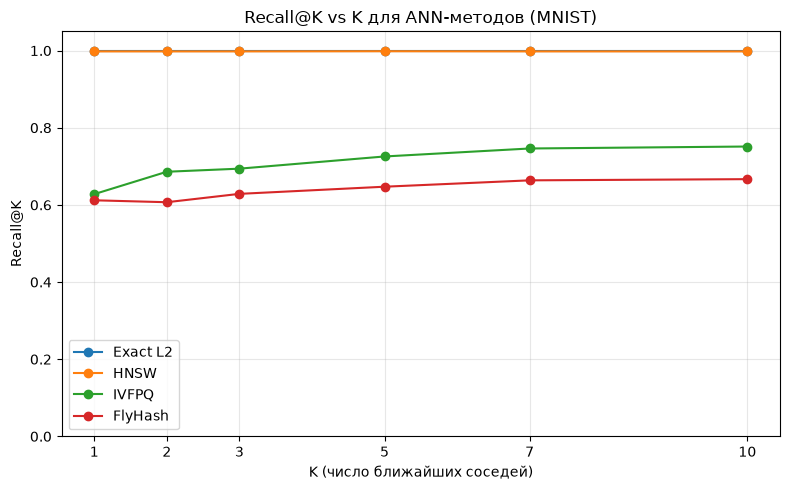

In [29]:
ks = [1, 2, 3, 5, 7, 10]

plt.figure(figsize=(8, 5))
for name, r in results.items():
    recalls = [calculate_recall_at_k(exact_indices, r["indices"], k) for k in ks]
    plt.plot(ks, recalls, marker="o", label=name)

plt.xlabel("K (число ближайших соседей)")
plt.ylabel("Recall@K")
plt.title("Recall@K vs K для ANN-методов (MNIST)")
plt.xticks(ks)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

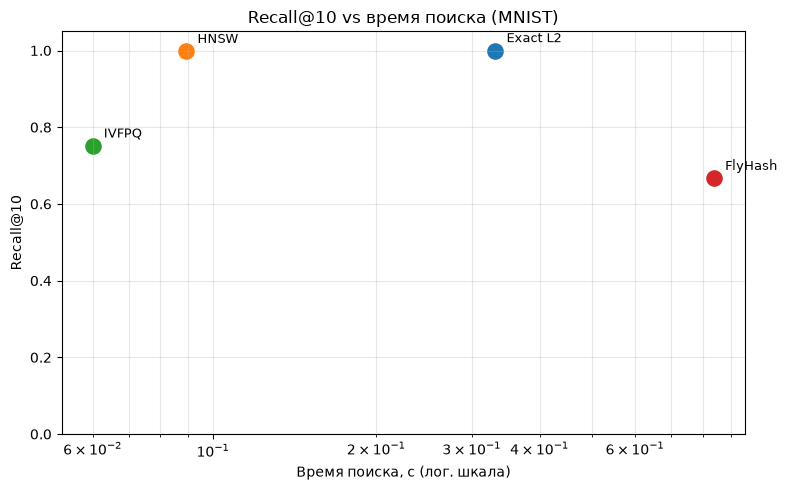

In [30]:
plt.figure(figsize=(8, 5))
for name, r in results.items():
    r10 = calculate_recall_at_k(exact_indices, r["indices"], 10)
    plt.scatter(r["search_time"], r10, s=120, label=name)
    plt.annotate(name, (r["search_time"], r10),
                 textcoords="offset points", xytext=(8, 6), fontsize=9)

plt.xlabel("Время поиска, с (лог. шкала)")
plt.ylabel("Recall@10")
plt.title("Recall@10 vs время поиска (MNIST)")
plt.xscale("log")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

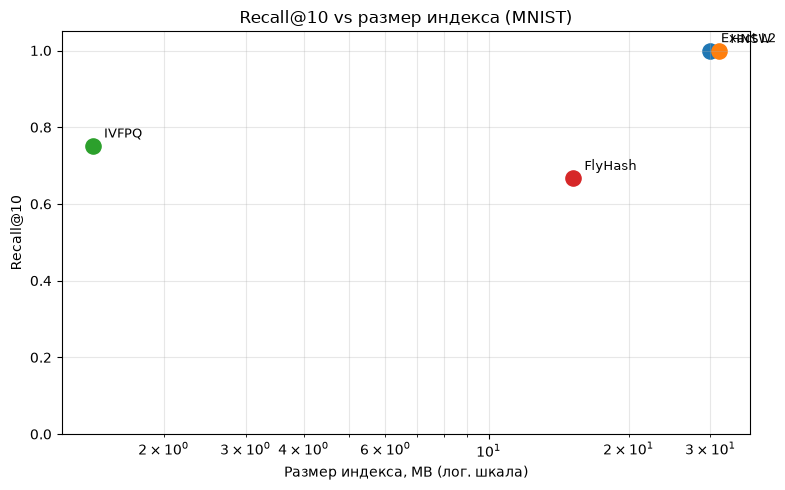

In [31]:
plt.figure(figsize=(8, 5))
for name, r in results.items():
    r10 = calculate_recall_at_k(exact_indices, r["indices"], 10)
    plt.scatter(r["index_mb"], r10, s=120, label=name)
    plt.annotate(name, (r["index_mb"], r10),
                 textcoords="offset points", xytext=(8, 6), fontsize=9)

plt.xlabel("Размер индекса, MB (лог. шкала)")
plt.ylabel("Recall@10")
plt.title("Recall@10 vs размер индекса (MNIST)")
plt.xscale("log")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

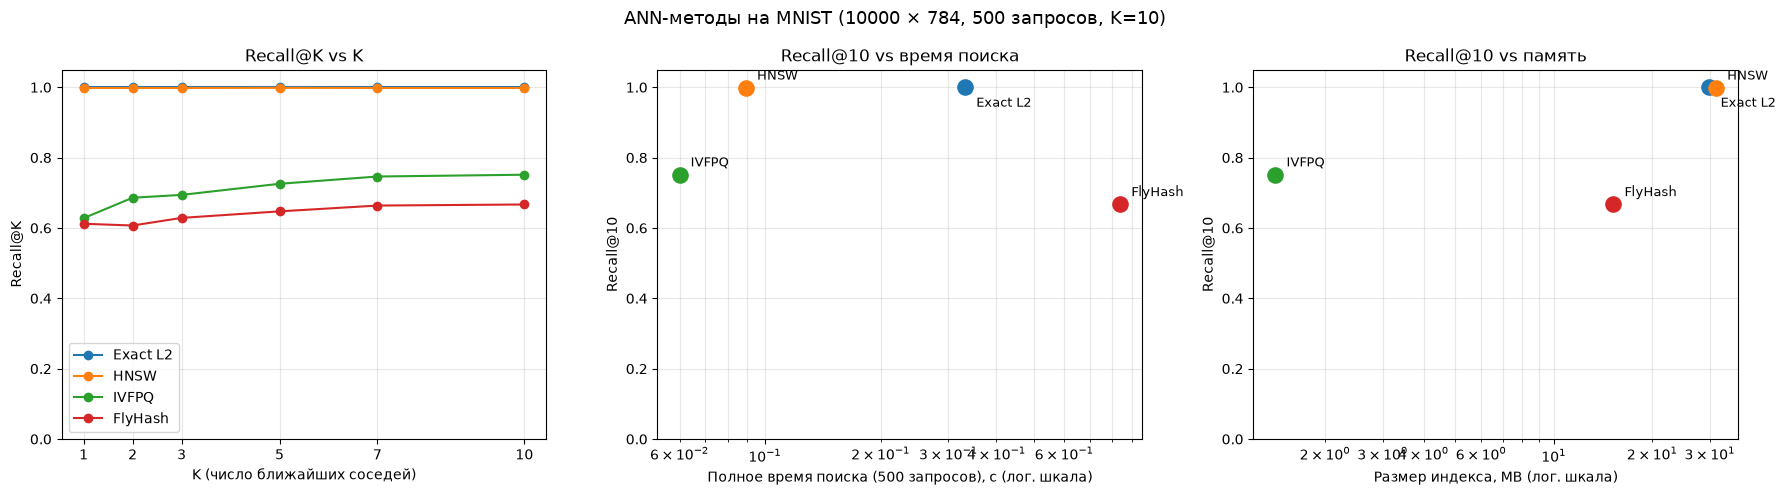

In [32]:
import numpy as np
import matplotlib.pyplot as plt


measured = {
    name: (r["build_time"], r["search_time"], r["index_mb"], r["memory_mb"])
    for name, r in results.items()
}
indices = {
    "Exact L2": exact_indices,
    "HNSW":     hnsw_indices,
    "IVFPQ":    ivfpq_indices,
    "FlyHash":  approx_indices_fly,
}

n_test = len(X_test)
ks = [1, 2, 3, 5, 7, 10]
names = list(measured)
colors = dict(zip(names, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
offsets = {"Exact L2": (8, -14), "HNSW": (8, 6), "IVFPQ": (8, 6), "FlyHash": (8, 6)}

r10 = {n: calculate_recall_at_k(exact_indices, indices[n], 10) for n in names}


def annotate(ax, x, y, name):
    ax.scatter(x, y, s=120, color=colors[name], zorder=3)
    ax.annotate(name, (x, y), textcoords="offset points",
                xytext=offsets[name], fontsize=9)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))


ax = axes[0]
for n in names:
    rec = [calculate_recall_at_k(exact_indices, indices[n], k) for k in ks]
    ax.plot(ks, rec, marker="o", label=n, color=colors[n])
ax.set_xlabel("K (число ближайших соседей)")
ax.set_ylabel("Recall@K")
ax.set_title("Recall@K vs K")
ax.set_xticks(ks)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()


ax = axes[1]
for n in names:
    annotate(ax, measured[n][1], r10[n], n)
ax.set_xscale("log")
ax.set_xlabel(f"Полное время поиска ({n_test} запросов), с (лог. шкала)")
ax.set_ylabel("Recall@10")
ax.set_title("Recall@10 vs время поиска")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, which="both")


ax = axes[2]
for n in names:
    annotate(ax, max(measured[n][2], 1e-2), r10[n], n)
ax.set_xscale("log")
ax.set_xlabel("Размер индекса, MB (лог. шкала)")
ax.set_ylabel("Recall@10")
ax.set_title("Recall@10 vs память")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, which="both")

fig.suptitle(f"ANN-методы на MNIST (10000 × 784, {n_test} запросов, K=10)", fontsize=13)
fig.tight_layout()
fig.savefig("benchmark_plots.png", dpi=150, bbox_inches="tight")
plt.show()